структура исходных данных:

In [18]:
import xlrd
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

file_name = 'ZnS.xls'
file_path = Path('data/raw') / file_name


book = xlrd.open_workbook(file_path)
sheet = book.sheet_by_index(0)

data = []
for row in range(sheet.nrows):
    data.append(sheet.row_values(row))


df = pd.DataFrame(data[1:], columns=data[0])

df.head()

,Time,OHM,,,Start Time,46209.534444
0,46209.534468,223943.984,0.1,,Interval,0.000058
1,46209.534583,224927.344,,,,
2,46209.534641,228039.744,,,Samples Completed,1117.0
3,46209.534699,236399.024,,,,
4,46209.534757,236618.128,,,Last Point on Chart,1117.0


колонка времени читается не правильно (проблема с форматом?), техническая информация из 4 и 5 колонок не нужна
используются 2 и 3 столбцы

In [19]:
df = df.iloc[:, [1, 2]]
df.columns = ['OHM', 'P, mV']
df.head()

,OHM,"P, mV"
0,223943.984,0.1
1,224927.344,
2,228039.744,
3,236399.024,
4,236618.128,


предобработка данных
заполняю пропущенные значения давления

In [20]:
df['P, mV'] = pd.to_numeric(df['P, mV'], errors='coerce')

fill_direction = 'up'
#fill_direction = 'dn'

if fill_direction == 'up':
	df['P, mV'] = df['P, mV'].ffill()
else:
	df['P, mV'] = df['P, mV'].bfill()

df['block_id'] = (df['P, mV'] != df['P, mV'].shift()).cumsum()

df.head()

,OHM,"P, mV",block_id
0,223943.984,0.1,1
1,224927.344,0.1,1
2,228039.744,0.1,1
3,236399.024,0.1,1
4,236618.128,0.1,1


измерения при одном давлении проводятся около 5 минут, поэтому усредняем последние 25 значений

In [21]:
#среднее последних 25 значений
def avg_last(group):
	last = group['OHM'].tail(25)
	return pd.Series({
		'P, mV': group['P, mV'].iloc[0],
		'R, OHM': last.mean()
	})

result = df.groupby('block_id').apply(avg_last).reset_index(drop=True)

result

,"P, mV","R, OHM"
0,0.1,365869.041920
1,0.3,356815.726080
2,0.5,217906.473600
3,0.7,161169.498240
4,0.9,12292.645472
5,1.1,6326.729472
6,1.3,4147.526656
7,1.5,2693.651462
8,1.7,1968.273542
9,1.9,1335.978906


сохраняем результат

In [22]:
name = Path(file_name).stem
output_file = Path('data/processed') / f"{name}_averaged.xlsx"

result.to_excel(output_file, index=False)

строим график

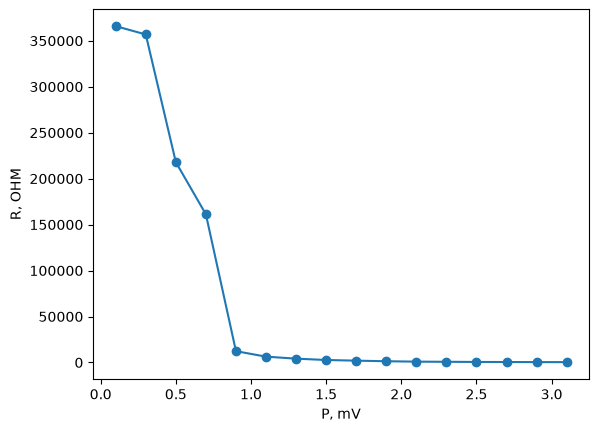

In [23]:
plt.plot(
	result['P, mV'],
	result['R, OHM'],
	marker='o'
)

plt.xlabel('P, mV')
plt.ylabel('R, OHM')

graph_file = f"graph_{name}_averaged.png"

#plt.savefig(graph_file)
#plt.close()
plt.show()